![title](https://i.imgur.com/XPBIVRh.png)
 <!https://imgur.com/a/weIMgzk>
---

<!-- https://imgur.com/a/BZQ6u9Z -->
<!-- https://imgur.com/a/h2gBJGh -->


# Task 6 - Generative Adversarial Network


So far in this course, all the applications of neural networks that we have explored have been **DISCRIMINATIVE MODELS**: that take an input and are trained to produce a labeled output.

 This has ranged from straightforward classification of image categories to sentence generation (which was still phrased as a classification problem, our labels were in vocabulary space and we’d learned a recurrence to capture multi-word labels).

In this notebook, we will expand our repetoire, and build **GENERATIVE MODELS** using neural networks.

Specifically, we will learn how to build models which generate novel images that resemble a set of training images.


Write down your Name and Student ID

In [1]:
## --- start your code here ----

NIM  = 103012350550
Nama = "Mohamed Ali Ibrahim"

## --- end your code here ----

In [2]:
# --- AUTOGRADESEED06: JANGAN DIHAPUS/DIUBAH ---
# Menghasilkan pengali loss generator unik per NIM, dipakai di sanity check
# AUTOGRADECHECK06 di bawah (bukan untuk training Vanilla/LS/DC-GAN 10 epoch
# yang sebenarnya - itu tetap pakai generator_loss()/ls_generator_loss() asli
# tanpa pengali, supaya hasil gambar yang didapat semua mahasiswa bisa
# dibandingkan ke Expected Output yang sama).
import hashlib

SEED = int(hashlib.sha256(str(NIM).strip().encode()).hexdigest(), 16) % (2**31)
GEN_LOSS_MULT = round(1.0 + (SEED % 50) / 100, 2)  # 1.00 - 1.49

print("Seed (dari NIM):", SEED)
print("Generator loss multiplier unik (dari NIM):", GEN_LOSS_MULT)


Seed (dari NIM): 2144828018
Generator loss multiplier unik (dari NIM): 1.18


---
---
# [Part 0] What is GAN?

In 2014, [Goodfellow et al.](https://arxiv.org/abs/1406.2661) presented a method for training generative models called Generative Adversarial Networks (GANs for short).

GANs are not the only way to train a generative model! For other approaches to generative modeling check out the [deep generative model chapter](http://www.deeplearningbook.org/contents/generative_models.html) of the Deep Learning [book](http://www.deeplearningbook.org).

As you've tried before, another popular way of training neural networks as generative models is Variational Autoencoders (co-discovered [here](https://arxiv.org/abs/1312.6114) and [here](https://arxiv.org/abs/1401.4082)). Variational autoencoders combine neural networks with Variational inference to train deep generative models. These models tend to be far more stable and easier to train but currently don't produce samples that are as pretty as GANs.



Since 2014, GANs have exploded into a foundational research area within generative AI, with massive [workshops](https://sites.google.com/site/nips2016adversarial/) and thousands of breakthrough [papers](https://github.com/hindupuravinash/the-gan-zoo) published over the past decade. Compared to other approaches for generative models, they often produce the highest quality, sharpest samples but remain among the most difficult and finicky models to stabilize during training.

Improving the stability and robustness of GAN training is a cornerstone of deep learning research, leading to advanced derivatives like WGAN-GP, StyleGAN, and modern multi-modal diffusion integrations.

2017 is said to be the year of GAN with so many research and papers published in investigating and improving GANs application.

Several popular GAN architectures and implementation are: [WGAN](https://arxiv.org/abs/1701.07875), [WGAN-GP](https://arxiv.org/abs/1704.00028), [CGAN](https://arxiv.org/abs/1411.1784), [InfoGAN](https://arxiv.org/abs/1606.03657), [Pix2Pix](https://arxiv.org/abs/1611.07004), [CycleGAN](https://arxiv.org/abs/1703.10593), and many others.


---
## 1 - GAN Networks

In a GAN, we build two different neural networks.

Our first network is a traditional classification network, called the **DISCRIMINATOR**. We will train the discriminator to take images, and classify them as being real (belonging to the training set) or fake (not present in the training set).

Our other network, called the **GENERATOR**, will take random noise as input and transform it using a neural network to produce images. The goal of the generator is to fool the discriminator into thinking the images it produced are real.

<br>

We can think of this back and forth process of the generator ($G$) trying to fool the discriminator ($D$), and the discriminator trying to correctly classify real vs. fake as a minimax game:

$$\underset{G}{\text{minimize}}\; \underset{D}{\text{maximize}}\; \mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$
where
* $z \sim p(z)$ are the random noise samples,
* $G(z)$ are the generated images using the neural network generator $G$, and
* $D$ is the output of the discriminator, specifying the probability of an input being real.

<br>

In [Goodfellow et al.](https://arxiv.org/abs/1406.2661), they analyze this minimax game and show how it relates to minimizing the Jensen-Shannon divergence between the training data distribution and the generated samples from $G$.

---
## 2 - GAN Objectives

To optimize this minimax game, we will aternate between taking gradient *descent* steps on the objective for $G$, and gradient *ascent* steps on the objective for $D$:
1. update the **generator** ($G$) to minimize the probability of the **discriminator making the CORRECT choice**.

2. update the **discriminator** ($D$) to maximize the probability of the **discriminator making the CORRECT choice**.

While these updates are useful for analysis, they do not perform well in practice. Instead, we will use a different objective when we update the generator: maximize the probability of the **discriminator making the INCORRECT choice**. This small change helps to allevaiate problems with the generator gradient vanishing when the discriminator is confident.

<br>

This is the standard update used in most GAN papers, and was used in the original paper from [Goodfellow et al.](https://arxiv.org/abs/1406.2661).

---
## 3 - In this Assignment

In this assignment, we will alternate the following updates:

1. Update the generator ($G$) to maximize the probability of the discriminator making the incorrect choice on generated data:

$$\underset{G}{\text{maximize}}\;  \mathbb{E}_{z \sim p(z)}\left[\log D(G(z))\right]$$

2. Update the discriminator ($D$), to maximize the probability of the discriminator making the correct choice on real and generated data:

$$\underset{D}{\text{maximize}}\; \mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] + \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$

---
## 4 - MNIST GAN

GANs are notoriously finicky with hyperparameters, and also require many training epochs. In order to make this assignment approachable without a GPU, we will be working on the MNIST dataset, which is 60,000 training and 10,000 test images.

Each picture contains a centered image of white digit on black background (0 through 9). This was one of the first datasets used to train convolutional neural networks and it is fairly easy -- a standard CNN model can easily exceed 99% accuracy.

<br>


Here's an example of what your outputs from the 3 different models you're going to train should look like... note that GANs are sometimes finicky, so your outputs might not look exactly like this... this is just meant to be a *rough* guideline of the kind of quality you can expect:

<br>

<center>
<img src='https://image.ibb.co/d3SZsq/gan-outputs-pytorch.png'>

---
---
# [Part 1] Import Libraries and Load Data

---
## 1 - Import Libraries

Import requiered libraries

In [3]:
!pip install torchinfo -q
!pip install graphviz torchview -q


[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip

[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [4]:
import torch
from torch import nn, optim
from torch.nn import init
from torch.utils.data import DataLoader, TensorDataset

import torchvision
import torchvision.datasets as dset
import torchvision.transforms as T

import os, shutil, glob
import imageio.v2 as imageio
import numpy as np

import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec

from torchview import draw_graph
from IPython.display import Image, display
from torchinfo import summary

%matplotlib inline
plt.rcParams['figure.figsize'] = (12.0, 10.0) # set default size of plots
plt.rcParams['image.interpolation'] = 'nearest'
plt.rcParams['image.cmap'] = 'gray'

np.set_printoptions(precision=5)

Check target hardware acceleration device

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

Using device: cpu


---
## 2 - Load MNIST Dataset

Load MNIST dataset and process for minibatch. In previous exercise, we use test dataset as validation. In this exercise, we will use actual validation data taken from training data.

---
### a. MNIST Parameters

The default parameters will take $5,000$ of the training examples and place them into a validation dataset.

The data will be saved into a folder called `MNIST_data`.

In [6]:
NUM_TRAIN  = 50000
NUM_VAL    = 5000
NOISE_DIM  = 96
batch_size = 128

---
### b. Image Sampler

Class below is a sampler routine used to sequentially samples MNIST images  from some offset.

In [7]:
from torch.utils.data import sampler

class ChunkSampler(sampler.Sampler):
    def __init__(self, num_samples, start=0):
        self.num_samples = num_samples
        self.start = start

    def __iter__(self):
        return iter(range(self.start, self.start + self.num_samples))

    def __len__(self):
        return self.num_samples


---
### c. Load MNIST images

Load data using DataLoader

In [8]:
mnist_data = dset.MNIST(root='./data', train=True, download=True, transform=T.ToTensor())

loader_train = DataLoader(mnist_data, batch_size=batch_size, sampler=ChunkSampler(NUM_TRAIN, 0))
loader_val   = DataLoader(mnist_data, batch_size=batch_size, sampler=ChunkSampler(NUM_VAL, NUM_TRAIN))

---
## 3 - Load File Checker

we also provided a reference matrix to check whether the matrix produced by your implementation matched our expected output

In [9]:
import urllib.request

urllib.request.urlretrieve(
    'https://raw.githubusercontent.com/CNN-ADF/Task2019/master/resources/gan-checks.npz',
    'gan-checks.npz'
)

answers = dict(np.load('gan-checks.npz'))

---
## 4 - Helper Functions

We provide you with some helper functions needed for this exercise

You don't need to do anything in these cells.

---
### a. Show Images
function to display a set of image in a two-dimensional grid

In [10]:
def show_images(images):
    # images reshape to (batch_size, D)
    images  = np.reshape(images, [images.shape[0], -1])
    sqrtn   = int(np.ceil(np.sqrt(images.shape[0])))
    sqrtimg = int(np.ceil(np.sqrt(images.shape[1])))

    fig = plt.figure(figsize=(sqrtn, sqrtn))
    gs  = gridspec.GridSpec(sqrtn, sqrtn)
    gs.update(wspace=0.05, hspace=0.05)

    for i, img in enumerate(images):
        ax = plt.subplot(gs[i])
        plt.axis('off')
        ax.set_xticklabels([])
        ax.set_yticklabels([])
        ax.set_aspect('equal')
        plt.imshow(img.reshape([sqrtimg,sqrtimg]))


Run the code below to show some MNIST data sample

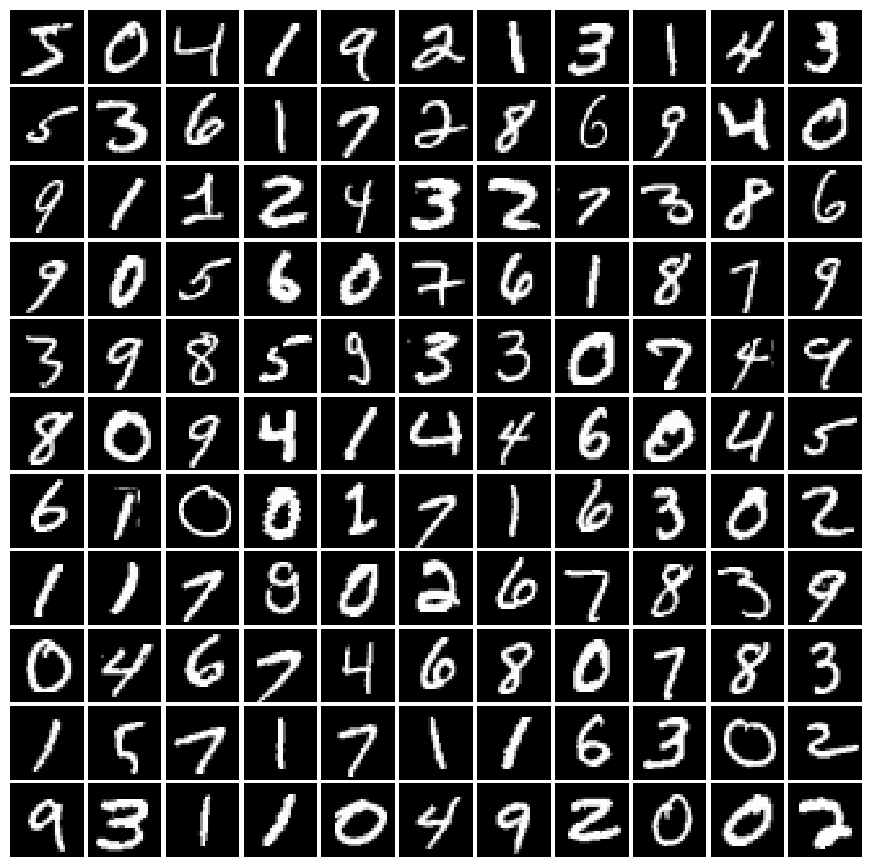

In [11]:
imgs = next(iter(loader_train))[0]
imgs = imgs.view(batch_size, 784).numpy().squeeze()

show_images(imgs[:121])
plt.show()

**EXPECTED OUTPUT**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/nAJtiqx.png" height="300">

---
### b. Preprocess Image

`preprocess_img()` function is used to preprocess MNIST dataset images by normalizing it to range of $-1..1$

and another `deprocess_img()` function to return the image back to range of $0..1$

In [12]:
def preprocess_img(x):
    return 2 * x - 1.0

def deprocess_img(x):
    return (x + 1.0) / 2.0

---
### c. Random Noise

Similar to Variational Autoencoder from previous exercise, GAN Generator network generate an image from a input random vector, called `seed` or `noise`

It is preferable that the seed is uniformly distributed in range of $(-1..1)$

However, PyTorch only provides random uniform generator &nbsp;`torch.rand()`&nbsp; function which generate a PyTorch Tensor in range of $(0..1)$

So we need to define a function to scale and shift it to the desired range

In [13]:
def sample_noise(batch_size, dim):
    noise = torch.rand((batch_size, dim), device=device) *2 -1

    return noise

---
### d. Xavier Weight Initializer


We also provide a weight initializer (and call it for you) that uses Xavier initialization instead of PyTorch's uniform default.

In [14]:
def initialize_weights(m):
    if isinstance(m, nn.Linear) or isinstance(m, nn.ConvTranspose2d):
        init.xavier_uniform_(m.weight.data)

---
### e. Relative Error Function

Function to calculate difference between your matrix and our expected results

In [15]:
def rel_error(x,y):
    return np.max(np.abs(x - y) / (np.maximum(1e-8, np.abs(x) + np.abs(y))))

---
### f. Clean Summary
Same as previous exercise, we will use this `clean_summary` function to print a much cleaner version.

In [16]:
def clean_summary(*args, **kwargs):
    # Force torchinfo to show depth so we can read the tree indentation

    kwargs["col_names"] = ["input_size", "output_size", "num_params"]

    stats = summary(*args, **kwargs)
    lines = str(stats).split('\n')

    # Dynamically extract where columns start based on the header line
    header_idx = next(idx for idx, line in enumerate(lines) if "Layer (type" in line)
    header     = lines[header_idx]

    # Find column indices for Input Shape and Output Shape columns
    input_col_start  = header.find("Input Shape")
    num_params_start = header.find("Param #")

    clean_lines = []
    for i in range(len(lines)):
        # Instantly keep all structural decorators, headers, and bottom metric totals
        if "===" in lines[i] or "Total params" in lines[i] or "Layer (type" in lines[i] or "size (MB)" in lines[i]:
            clean_lines.append(lines[i])
            continue

        # Analyze tree depth indents (looking ahead to see if the next row is a child)
        if i + 1 < len(lines):
            current_indent = len(lines[i])   - len(lines[i].lstrip(' │├└'))
            next_indent    = len(lines[i+1]) - len(lines[i+1].lstrip(' │├└'))

            # If the next layer is deeper, this current layer is a parent tree container!
            if next_indent > current_indent:
                # Strip out shapes from the parent line, leaving just its name/tree markings and params
                layer_name_part = lines[i][:input_col_start]
                param_part      = lines[i][num_params_start:]

                # Fill the space between the name and the parameters with empty spaces
                middle_spacing = " " * (num_params_start - input_col_start)

                clean_lines.append(f"{layer_name_part}{middle_spacing}{param_part}")
                continue

        # If it's a leaf node/child node, keep the line exactly as torchinfo generated it
        clean_lines.append(lines[i])

    print('\n'.join(clean_lines))

---
### g. Generate GIF

This function generate a GIF animation from the saved images and display it to your notebook

In [17]:
def show_gif(base_dir, anim_file):
    with imageio.get_writer(anim_file, mode='I', loop=0) as writer:
        filenames = glob.glob(base_dir+'/image*.png')
        filenames = sorted(filenames)
        for filename in filenames:
            image = imageio.imread(filename)
            for i in range(3):
              writer.append_data(image)
        image = imageio.imread(filename)
        writer.append_data(image)

    print('GIF saved as', anim_file)

    with open(anim_file,'rb') as f:
      display(Image(data=f.read(), format='png'))

---
---
# [Part 2] Vanilla GAN

For starter, let's build our Vanilla GAN using Normal Neural Network (Linear Layer, not Convolutional Layer)

After we build the training function for Vanilla GAN, for the other architecture, it's as simple as replacing the Loss and the Networks (Generator and Discriminator network).

---
## 1 - Discriminator Model
Our first step is to build a discriminator. Fill in the architecture as part of the `nn.Sequential` constructor in the function below. All fully connected layers should include bias terms.

The architecture is:
<pre>
    * <b>Flatten</b> layer
    * <b>Linear</b> layer with <font color='blue'><b>256</b></font> neurons and <b>LeakyReLU</b> activation with alpha <font color='blue'><b>0.01</b></font>
    * <b>Linear</b> layer with <font color='blue'><b>256</b></font> neurons and <b>LeakyReLU</b> activation with alpha <font color='blue'><b>0.01</b></font>
    * <b>Linear</b> layer with <font color='blue'><b>1</b></font> neuron output,
</pre>


Recall Leaky ReLU:
  * Leaky ReLU nonlinearity computes&nbsp; $f(x) = \max(\alpha x, x)$ &nbsp;for some fixed constant $\alpha$;
  * for this architecture, we set&nbsp; $\alpha=0.01$.

 <br>

The output of the discriminator should have shape `[batch_size, 1]`, and contain real numbers corresponding to the scores that each of the `batch_size` inputs is a real image.


---
#### <font color='red'>**EXERCISE:** </font>
Build and return a PyTorch model implementing the architecture above.

In [18]:
def discriminator():
    model = nn.Sequential(

        # add nn.Flatten() layer
        nn.Flatten(),

        # add nn.Linear() layer with in features 28*28 and out features 256
        nn.Linear(28 * 28, 256),

        # add nn.LeakyRelu() with alpha 0.01
        nn.LeakyReLU(0.01),

        # add nn.Linear() layer with in and out features 256
        nn.Linear(256, 256),

        # add nn.LeakyRelu() with alpha 0.01
        nn.LeakyReLU(0.01),

        # add nn.Linear() layer with in features 256 and out feature 1
        nn.Linear(256, 1)
    )
    return model

Test to make sure the number of parameters in the discriminator is correct:

In [19]:
model = discriminator()

clean_summary(model, (1, 1, 28, 28))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                                                                                   --
├─Flatten: 1-1                           [1, 1, 28, 28]            [1, 784]                  --
├─Linear: 1-2                            [1, 784]                  [1, 256]                  200,960
├─LeakyReLU: 1-3                         [1, 256]                  [1, 256]                  --
├─Linear: 1-4                            [1, 256]                  [1, 256]                  65,792
├─LeakyReLU: 1-5                         [1, 256]                  [1, 256]                  --
├─Linear: 1-6                            [1, 256]                  [1, 1]                    257
Total params: 267,009
Trainable params: 267,009
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 0.27
Input size (MB): 0.00
Forward/backward pass size (MB): 0.00
Params size (MB): 1.07
Estimated Total Size (

**Expected Result**:
<pre>
==========================================================================
Layer (type:depth-idx)       Input Shape       Output Shape    Param #
==========================================================================
Sequential                                                     --
├─Flatten: 1-1               [1, 1, 28, 28]    [1, 784]        --
├─Linear: 1-2                [1, 784]          [1, 256]        200,960
├─LeakyReLU: 1-3             [1, 256]          [1, 256]        --
├─Linear: 1-4                [1, 256]          [1, 256]        65,792
├─LeakyReLU: 1-5             [1, 256]          [1, 256]        --
├─Linear: 1-6                [1, 256]          [1, 1]          257
==========================================================================
Total params: 267,009
Trainable params: 267,009

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:17036): Pango-WARNING **: 19:53:55.391: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


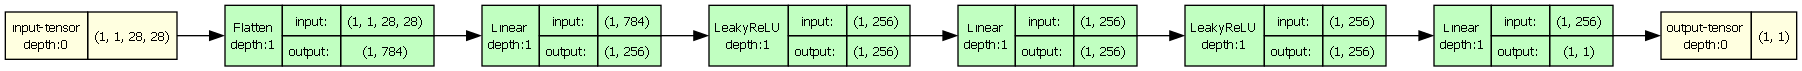

In [20]:
graphviz_bin = r'C:\Program Files\Graphviz\bin'
if os.path.isdir(graphviz_bin):
    os.environ['PATH'] = graphviz_bin + os.pathsep + os.environ.get('PATH', '')

model_graphq = draw_graph(model, input_size=(1, 1, 28, 28), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("model_d", format="png")
display(Image(filename="model_d.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/iKSgDuh.png" width="800">

---
## 2 - Generator Model

Now to build the generator network


The architecture is:
<pre>
    * <b>Linear</b> layer with <font color='blue'><b>1024</b></font> neurons and <b>ReLU</b> activation
    * <b>Linear</b> layer with <font color='blue'><b>1024</b></font> neurons and <b>ReLU</b> activation
    * <b>Linear</b> layer with <font color='blue'><b>28*28</b></font> neurons and  <b>TanH</b> activation
</pre>


---
#### <font color='red'>**EXERCISE:** </font>
Build and return a PyTorch model implementing the architecture above.

In [21]:
def generator(noise_dim=96):
    """
    Build and return a PyTorch model implementing the architecture above.
    """
    model = nn.Sequential(

        # add nn.Linear() layer with in features noise_dim and out features 1024
        nn.Linear(noise_dim, 1024),

        # add nn.Relu() activation
        nn.ReLU(),

        # add nn.Linear() layer with in and out features 1024
        nn.Linear(1024, 1024),

        # add nn.Relu() activation
        nn.ReLU(),

        # add nn.Linear() layer with in features 1024 and out feature 28*28
        nn.Linear(1024, 28 * 28),

        # add nn.Tanh() activation
        nn.Tanh()
    )
    return model

Test to make sure the number of parameters in the generator is correct:

In [22]:
model = generator(4)

clean_summary(model, (1,4))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                                                                                   --
├─Linear: 1-1                            [1, 4]                    [1, 1024]                 5,120
├─ReLU: 1-2                              [1, 1024]                 [1, 1024]                 --
├─Linear: 1-3                            [1, 1024]                 [1, 1024]                 1,049,600
├─ReLU: 1-4                              [1, 1024]                 [1, 1024]                 --
├─Linear: 1-5                            [1, 1024]                 [1, 784]                  803,600
├─Tanh: 1-6                              [1, 784]                  [1, 784]                  --
Total params: 1,858,320
Trainable params: 1,858,320
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 1.86
Input size (MB): 0.00
Forward/backward pass size (MB): 0.02
Params size (MB): 7.43
Estimated Tot

**Expected Result**:
<pre>
==========================================================================
Layer (type:depth-idx)       Input Shape       Output Shape    Param #
==========================================================================
Sequential                                                     --
├─Linear: 1-1                [1, 4]            [1, 1024]       5,120
├─ReLU: 1-2                  [1, 1024]         [1, 1024]       --
├─Linear: 1-3                [1, 1024]         [1, 1024]       1,049,600
├─ReLU: 1-4                  [1, 1024]         [1, 1024]       --
├─Linear: 1-5                [1, 1024]         [1, 784]        803,600
├─Tanh: 1-6                  [1, 784]          [1, 784]        --
==========================================================================
Total params: 1,858,320                                       
Trainable params: 1,858,320

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:18904): Pango-WARNING **: 19:53:55.791: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


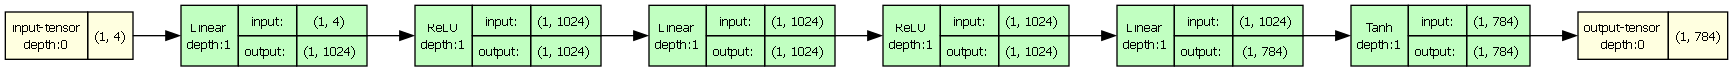

In [23]:
graphviz_bin = r'C:\Program Files\Graphviz\bin'
if os.path.isdir(graphviz_bin):
    os.environ['PATH'] = graphviz_bin + os.pathsep + os.environ.get('PATH', '')

model_graphq = draw_graph(model, input_size=(1, 4), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("model_g", format="png")
display(Image(filename="model_g.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/plUz01u.png" width="800">

---
---
# [Part 3] GAN Loss

Compute the generator and discriminator loss.

The generator loss is:

$$
\ell_G  =  -\mathbb{E}_{z \sim p(z)}\left[\log D(G(z))\right]
$$

and the discriminator loss is:

$$
\ell_D = -\mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] - \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]
$$

<br>

**Note** that these are negated from the equations presented earlier as we will be ***MINIMIZING*** these losses.

<br>

Instead of computing the expectation of $\log D(G(z))$, $\log D(x)$ and $\log \left(1-D(G(z))\right)$,

we will be averaging over elements of the minibatch, so make sure to combine the loss by averaging instead of summing.

---
## 1 - Discriminator Loss
Discriminator Loss calculate the total loss of Discriminator Model in recognizing real images and fake images.

The loss formula is as follow:
$$ \ell_D = -\mathbb{E}_{x \sim p_\text{data}}\left[\log D(x)\right] - \mathbb{E}_{z \sim p(z)}\left[\log \left(1-D(G(z))\right)\right]$$

or in simple term:

```python
      loss = loss_real + loss_fake
```

where
* `loss_real` is the binary cross entropy loss result between `logits_real` and `ones` matrix,

* while `loss_fake` is the binary cross entropy loss result between `logits_fake` and `zeros` matrix.

Given a score $s\in\mathbb{R}$ and a label $y\in\{0, 1\}$, the Binary Cross Entropy loss is

$$ bce(s, y) = -y * \log(s) - (1 - y) * \log(1 - s) $$

In PyTorch, this is done by instantiating `nn.BCEWithLogitsLoss()` class

---
#### <font color='red'>**EXERCISE:** </font>

Implement the Discriminator Loss as  described above.

In [24]:
# define criterion as nn.BCEWithLogitsLoss()
criterion = nn.BCEWithLogitsLoss()  # SOLUTION

In [25]:
def discriminator_loss(logits_real, logits_fake):

    # Generate GT targets for real images of ones with the same shape of logits_real
    # call torch.ones_like() with input logits real
    labels_real = torch.ones_like(logits_real)

    # Calculates the BCE loss for real samples
    # call criterion() with input logits real and labels real
    loss_real = criterion(logits_real, labels_real)

    # Generate GT targets for fake images of zeros with the same shape of logits_fake
    # call torch.zeros_like() with input logits fake
    labels_fake = torch.zeros_like(logits_fake)

    # Calculates the BCE loss for fake samples
    # call criterion() with input logits fake and labels fake
    loss_fake = criterion(logits_fake, labels_fake)

    # Combines both independent loss terms
    return loss_real + loss_fake

Test your discriminator loss.

You should see errors < `1e-7`.

In [26]:
score_real = torch.tensor(answers['logits_real'], dtype=torch.float32, device=device)
score_fake = torch.tensor(answers['logits_fake'], dtype=torch.float32, device=device)

d_loss = discriminator_loss(score_real, score_fake).detach().cpu().numpy()
difference = rel_error(answers['d_loss_true'], d_loss)

assert difference < 1e-7, "Expected error too high"
print("Maximum error in d_loss: %g" % difference)
print("Exercise check passed!")

Maximum error in d_loss: 2.83811e-08
Exercise check passed!


**Expected Result**:
<pre>
Maximum error in d_loss: 3.97058e-09

---
## 2 - Generator Loss

Generator Model is trained to *fool* the Discriminator. It means that we want to maximize the log probability when predicting fake images.

Thus, the Generator Loss is calculated using a simple Binary Cross Entropy as follow:

$$\ell_G  =  -\mathbb{E}_{z \sim p(z)}\left[\log D(G(z))\right]$$

the `loss` calculates the binary cross entropy loss result between `logits_fake` and `ones` matrix

---
#### <font color='red'>**EXERCISE:** </font>

Implement the Generator Loss as  described above.

In [27]:
def generator_loss(logits_fake):

    # Generate fake targets for fake images of ones with the same shape of logits_fake
    # call torch.ones_like() with input logits fake
    labels_fake = torch.ones_like(logits_fake)

    # Calculates the BCE loss to see how successfully the generator fooled the discriminator
    # call criterion() with input logits fake and labels fake
    loss_fake = criterion(logits_fake, labels_fake)

    return loss_fake

Test your generator and discriminator loss. You should see errors < 1e-7.

In [28]:
score_fake = torch.tensor(answers['logits_fake'], dtype=torch.float32, device=device)

g_loss = generator_loss(score_fake).detach().cpu().numpy()
difference = rel_error(answers['g_loss_true'], g_loss)

assert difference < 1e-7, "Expected error too high"
print("Maximum error in g_loss: %g" % difference)
print("Exercise check passed!")

Maximum error in g_loss: 3.4188e-08
Exercise check passed!


**Expected Result**:
<pre>
Maximum error in g_loss: 3.4188e-08


---
---
# [Part 4] Training Function

---
## 1 - Adam Optimizer

To train our models, we will optimize it using Adam optimizer with a `1e-3` learning rate, beta1=`0.5`, beta2=`0.999`.

Note that training a model in PyTorch requires an [Optimizer](https://pytorch.org/docs/stable/optim.html) object to perform the step and weights update.

For that, we need two optimizers for each generator and discriminator models. And later, we need another four when we implement LS-GAN and DC-GAN. We set all of them use the same Adam optimizer with the same learning rate and betas.

Therefore, rather than defining each of optimizers one-by-one, let's build a function to get the optimizer for any given model. We'll use this to construct optimizers for the generators and discriminators for the rest of the notebook.


---
#### <font color='red'>**EXERCISE:** </font>

Construct and return an Adam optimizer for the model with `learning rate = 1e-3` and `betas = (0.5, 0.999)`.

In [29]:
def get_optimizer(model):

    # call optim.Adam() function with input model.parameters()
    # and set learning rate and betas as defined
    optimizer = optim.Adam(model.parameters(), lr=1e-3, betas=(0.5, 0.999))

    return optimizer

---
## 2 - Training Loop

Fill in the critical steps within the inner multi-batch iteration loop: zeroing gradients, calculating modern Binary Cross-Entropy objectives, and performing loss backpropagation steps.

---
#### <font color='red'>**EXERCISE:** </font>

    Complete the core execution steps inside the inner multi-batch iteration loop:
    1. Zero out model structural accumulation gradients using the respective solvers.
    2. Compute forward pass responses through the Discriminator network.
    3. Calculate the objective loss values using the defined criteria.
    4. Perform backpropagation via `.backward()` to compute gradients and execute weight optimization steps.

    


In [30]:
def train_gan(Discriminator, Generator, base_dir,
              show_every=250, batch_size=128, noise_size=96, num_epochs=10):
    """
    Train a GAN!

    Inputs:
    - Discriminator : Tuple of Discriminator package, containing:
      - D_model     : PyTorch models for the discriminator
      - D_solver    : torch.optim Optimizers for training
      - D_loss      : Functions to use for computing the discriminator loss.

    - Generator     : Tuple of Generator package, containing:
      - G_model     : PyTorch models for the generator
      - G_solver    : torch.optim Optimizers for training
      - G_loss      : Functions to use for computing the generator loss.

    - base_dir      : Directory to save the generated image example
    - show_every    : Show and save samples after every show_every iterations.
    - batch_size    : Batch size to use for training.
    - noise_size    : Dimension of the noise to use as input to the generator.
    - num_epochs    : Number of epochs over the training dataset to use for training.
    """

    # unpack Discriminator
    D_model, D_solver, D_loss = Discriminator

    # unpack Generator
    G_model, G_solver, G_loss = Generator

    # parameter setting
    iter_count = 0
    img_count  = 0
    seed_saved = sample_noise(batch_size, noise_size)

    # make directory for saving image
    if os.path.exists(base_dir):
        shutil.rmtree(base_dir)
    os.mkdir(base_dir)

    print('start training')
    for epoch in range(num_epochs):
        print('epoch: ', epoch+1)
        for x, _ in loader_train:
            if len(x) != batch_size:
                continue

            # ==========================================
            # 1. PREPARE DATA
            # ==========================================
            # get real images
            real_images = 2 * (x.to(device)- 0.5)

            # generate new fake seed
            # call sample_noise() with input batch_size and noise_size
            g_fake_seed = sample_noise(batch_size, noise_size)

            # generate fake images from fake seed
            # forward pass fake seed to G_model()
            fake_images = G_model(g_fake_seed)

            # ==========================================
            # 2. UPDATE DISCRIMINATOR (D)
            # ==========================================
            # Zero out accumulated gradients for discriminator
            # call zero_grad() from D_solver
            D_solver.zero_grad()

            # forward pass real images to D_model()
            logits_real = D_model(real_images)

            # forward pass fake images to D_model()
            # We DETACH here so D cannot backprop into G
            logits_fake = D_model(fake_images.detach().view(batch_size, 1, 28, 28))

            # Calculate D_loss() with input logits_real and logits_fake
            d_total_error = D_loss(logits_real, logits_fake)

            # backward the error
            # call backward() from d_total_error
            d_total_error.backward()

            # update discriminator weights
            # call step() from D_solver
            D_solver.step()

            # ==========================================
            # 3. UPDATE GENERATOR (G)
            # ==========================================

            # Zero out accumulated gradients for generator
            # call zero_grad() from G_solver
            G_solver.zero_grad()

            # forward pass fake images to D_model() once again but without detaching
            # to get logits fake through discriminator network
            gen_logits_fake = D_model(fake_images.view(batch_size, 1, 28, 28))

            # Calculate G_loss() with input gen_logits_fake
            g_error = G_loss(gen_logits_fake)

            # backward the error
            # call backward() from g_error
            g_error.backward()

            # update generator weights
            # call step() from G_solver
            G_solver.step()

            if (iter_count % show_every == 0):

                print('Iter: {}, D loss: {:.4}, G loss:{:.4}'.format(iter_count,d_total_error.item(),g_error.item()))

                # show randomly generated images from this iteration
                imgs_numpy = fake_images.detach().cpu().numpy()
                show_images(imgs_numpy[0:16])
                plt.show()

                # save images generated from the same initial seed
                # to visualize the generator progress along training
                filename    = base_dir+'/image_'+'{:03}'.format(img_count)+'.png'
                fake_images = G_model(seed_saved)
                imgs_numpy  = fake_images.detach().cpu().numpy()
                img_count   += 1

                show_images(imgs_numpy[0:16])
                plt.savefig(filename)
                plt.close()
                print()

            iter_count += 1

    print('training done')



Well, that's it

Now let's try to train a Vanilla GAN!

---
## 3 - Train Vanilla GAN

First we initialize both Generator and Discriminator models

---
#### <font color='red'>**AUTOGRADE (jangan dihapus):**</font> sanity check 1 iterasi training GAN dengan bobot personalisasi NIM


In [31]:
# --- AUTOGRADECHECK06: sanity check 1 iterasi training GAN (D+G update) ---
# --- dengan bobot loss generator personalisasi NIM sendiri (GEN_LOSS_MULT). ---
# Cuma 1 batch kecil (16 sampel), 1 update D dan 1 update G - model baru
# diinisialisasi (belum/tidak perlu dilatih) - murni memverifikasi forward +
# backward pass discriminator dan generator berjalan tanpa error, dan
# memakai GEN_LOSS_MULT milik NIM sendiri (bukan disalin dari mahasiswa lain).
check_batch_size = 16

D_check = discriminator().to(device)
G_check = generator(NOISE_DIM).to(device)
D_check_solver = get_optimizer(D_check)
G_check_solver = get_optimizer(G_check)

x_check, _ = next(iter(loader_train))
x_check = x_check[:check_batch_size].to(device)
real_images = 2 * (x_check - 0.5)

g_fake_seed = sample_noise(check_batch_size, NOISE_DIM)
fake_images = G_check(g_fake_seed)

D_check_solver.zero_grad()
logits_real = D_check(real_images)
logits_fake = D_check(fake_images.detach().view(check_batch_size, 1, 28, 28))
d_check_loss = discriminator_loss(logits_real, logits_fake)
d_check_loss.backward()
D_check_solver.step()

G_check_solver.zero_grad()
gen_logits_fake = D_check(fake_images.view(check_batch_size, 1, 28, 28))
g_check_loss = GEN_LOSS_MULT * generator_loss(gen_logits_fake)
g_check_loss.backward()
G_check_solver.step()

print("GEN_LOSS_MULT yang dipakai (personalisasi NIM):", GEN_LOSS_MULT)
print("Sanity D loss: {:.4f}, G loss (sudah dikali GEN_LOSS_MULT): {:.4f}".format(
    d_check_loss.item(), g_check_loss.item()))


GEN_LOSS_MULT yang dipakai (personalisasi NIM): 1.18
Sanity D loss: 1.3528, G loss (sudah dikali GEN_LOSS_MULT): 0.8235


In [32]:
# Make the discriminator
D_V = discriminator().to(device)

# Make the generator
G_V = generator(NOISE_DIM).to(device)

# Use the function you wrote earlier to get optimizers for the Discriminator and the Generator
D_solver = get_optimizer(D_V)
G_solver = get_optimizer(G_V)

# pack the model
D = ( D_V, D_solver, discriminator_loss )
G = ( G_V, G_solver, generator_loss )

Then train the models for 10 epochs for quick comparison.

start training
epoch:  1
Iter: 0, D loss: 1.392, G loss:0.7026


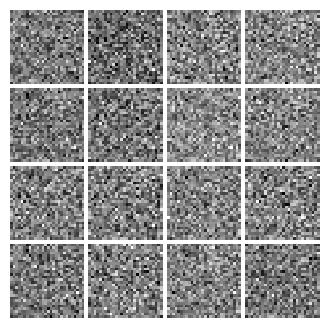


Iter: 250, D loss: 1.116, G loss:1.36


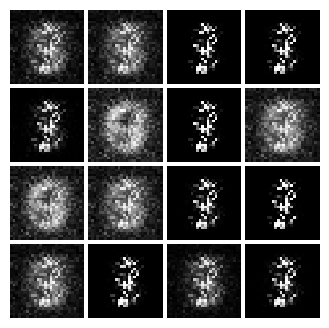


epoch:  2
Iter: 500, D loss: 1.378, G loss:1.168


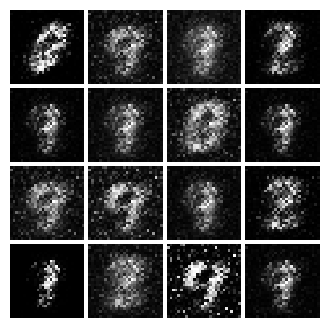


Iter: 750, D loss: 1.236, G loss:1.226


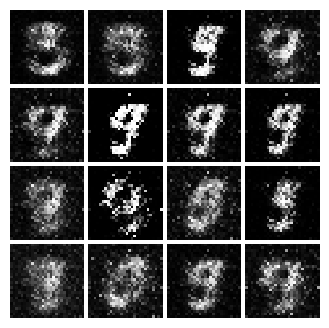


epoch:  3
Iter: 1000, D loss: 1.2, G loss:0.8937


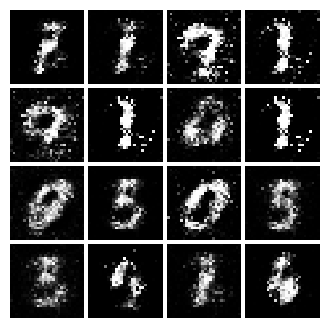


epoch:  4
Iter: 1250, D loss: 1.361, G loss:0.8734


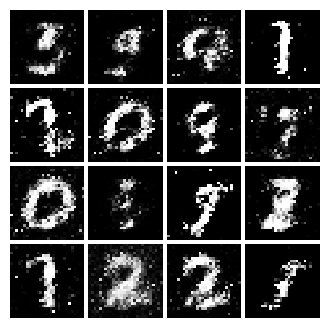


Iter: 1500, D loss: 1.158, G loss:1.049


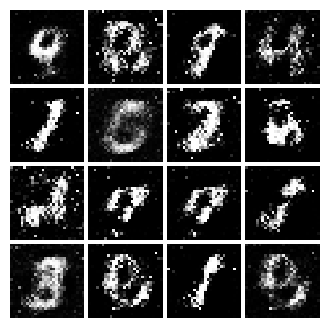


epoch:  5
Iter: 1750, D loss: 1.267, G loss:0.8457


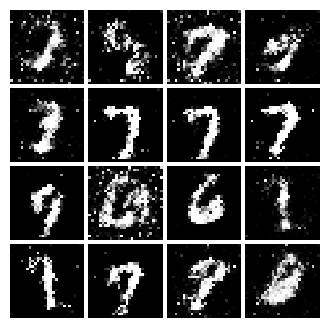


epoch:  6
Iter: 2000, D loss: 1.262, G loss:0.9412


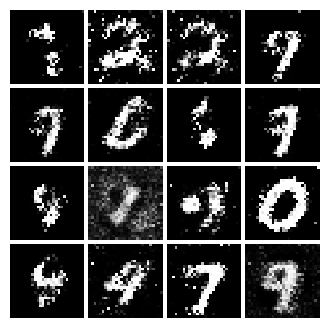


Iter: 2250, D loss: 1.303, G loss:0.9425


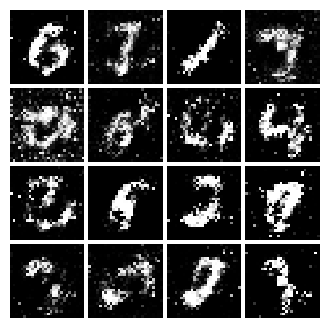


epoch:  7
Iter: 2500, D loss: 1.367, G loss:0.8171


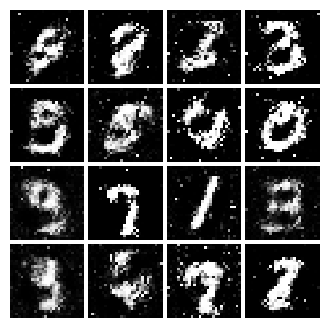


epoch:  8
Iter: 2750, D loss: 1.312, G loss:0.8171


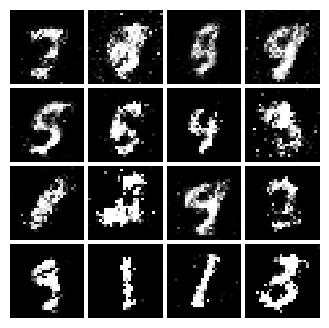


Iter: 3000, D loss: 1.37, G loss:0.8429


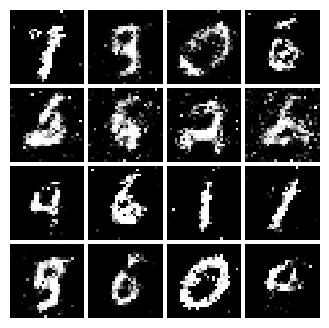


epoch:  9
Iter: 3250, D loss: 1.338, G loss:0.983


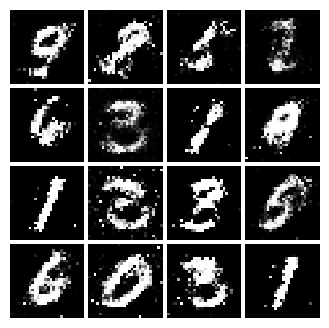


Iter: 3500, D loss: 1.274, G loss:0.8259


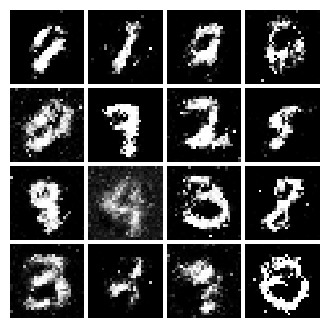


epoch:  10
Iter: 3750, D loss: 1.291, G loss:0.8339


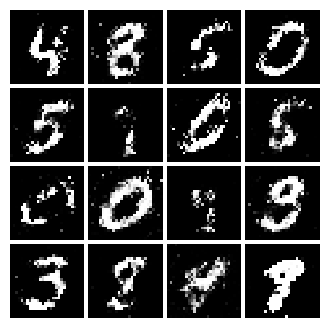


training done


In [33]:
base_dir = 'v_gan'

train_gan(D, G, base_dir, noise_size=NOISE_DIM, num_epochs=10)

**EXPECTED OUTPUT**:
<pre>
Discriminator Loss and Generator Loss might just hover around throughout 10 epochs, at around 1.4 and 0.8 respectively
</pre>

<img src="https://i.imgur.com/TXWNSsv.png" width="200"><img src="https://i.imgur.com/aNi3ix1.png" width="200">

Well that wasn't so hard, was it? In the iterations in the low 100s you should see black backgrounds, fuzzy shapes as you approach iteration 1000, and decent shapes, about half of which will be sharp and clearly recognizable as we pass 3000.

---
## 4 - Generate GIF

Now this just for fun, we combine the saved image generated from the same initial seed each epoch while training into a GIF animation

GIF saved as vanilla_gan.gif


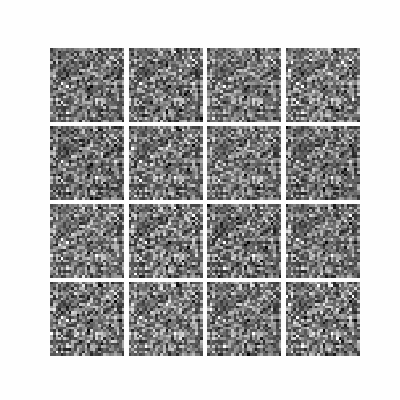

In [34]:
base_dir = 'v_gan'

show_gif(base_dir, 'vanilla_gan.gif')

---
---
# [Part 5] Least Squares GAN
We'll now look at [Least Squares GAN](https://arxiv.org/abs/1611.04076), a newer, more stable alernative to the original GAN loss function.

For this part, all we have to do is change the loss function and retrain the model.

<br>

We'll implement equation (9) in the paper, with the generator loss:
$$
\ell_G  =  \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[\left(D(G(z))-1\right)^2\right]$$

and the discriminator loss:

$$ \ell_D = \frac{1}{2}\mathbb{E}_{x \sim p_\text{data}}\left[\left(D(x)-1\right)^2\right] + \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[ \left(D(G(z))\right)^2\right]
$$

---
## 1 - LS-Discriminator Loss

In <font color='red'>**Vanilla GAN**</font>, the Discriminator Loss is the total <font color='red'>binary cross entropy loss</font> from discriminator when recognizing real images and fake images. And we train the network to **MINIMIZE** that total loss

<br>

In <font color='blue'>**LS-GAN**</font>, we change the BCE loss calculation into a simple <font color='blue'>score averaging</font>.

The idea is that since the Discriminator is a binary classification, it means that:

* we want the `real_score` when predicting **real images** to be **as close to 1 as possible**,

* and the `fake_score` when prediction **fake images** to be **as close to 0 as possible**.

<br>

Now if we ***flip*** the real scores by subtracting it with 1, this equalize our objectives so that now we want both `fake_score` and `real_score-1` to be as close to 0 as possible. And if we square the scores, now the values are always positive, and our objectives all become <font color='blue'>**minimization to 0**</font>.

<br>

As so we can just simply average the squared scores, and train the network to **MINIMIZE** the average

Thus we have:

$$
\ell_D = \frac{1}{2}\mathbb{E}_{x \sim p_\text{data}}\left[\left(D(x)-1\right)^2\right] + \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[ \left(D(G(z))\right)^2\right]
$$

or its just simply,

```python
    loss_real = mean( square( scores_real-1 ) )
    loss_fake = mean( square( scores_fake-0 ) )

    loss = 0.5 * loss_real + 0.5 * loss_fake
```

However, instead of computing the expectation, we will be averaging over elements of the minibatch, so make sure to combine the loss by averaging instead of summing.

When plugging in for $D(x)$ and $D(G(z))$ use the direct output from the discriminator (`scores_real` and `scores_fake`).

---
#### <font color='red'>**EXERCISE:** </font>

Implement the Least Squares GAN Discriminator loss as defined above.
You might find one or two lines are unnecessary, but they're there for the sake of symmetry

In [35]:
def ls_discriminator_loss(scores_real, scores_fake):

    # ---------------------------------------------------------
    # Calculate loss_real:
    # ---------------------------------------------------------
    # Create a tensor of ones matching scores_real shape and device
    # call torch.ones_like() with input scores real
    targets_real = torch.ones_like(scores_real)

    # Compute the difference between predictions and targets
    # real scores - real target
    diff_real = scores_real - targets_real

    # Square the difference values
    # call torch.square() with input diff real
    squared_real = torch.square(diff_real)

    # Average the squared values over the minibatch
    # call torch.mean() with input squared real
    loss_real = torch.mean(squared_real)


    # ---------------------------------------------------------
    # Calculate loss_fake:
    # ---------------------------------------------------------
    # Create a tensor of zeros matching scores_fake shape and device
    # call torch.zeros_like() with input scores fake
    targets_fake = torch.zeros_like(scores_fake)

    # Compute the difference between predictions and targets
    # fake scores - fake target
    diff_fake = scores_fake - targets_fake

    # Square the difference values
    # call torch.square() with input diff fake
    squared_fake = torch.square(diff_fake)

    # Average the squared values over the minibatch
    # call torch.mean() with input squared fake
    loss_fake = torch.mean(squared_fake)

    # average the loss_real and loss_fake
    loss = 0.5 * (loss_real + loss_fake)

    return loss

Before running a GAN with our new loss function, let's check it:

You should see error <`1e-7`

In [36]:
score_real = torch.tensor(answers['logits_real'], dtype=torch.float32, device=device)
score_fake = torch.tensor(answers['logits_fake'], dtype=torch.float32, device=device)

d_loss = ls_discriminator_loss(score_real, score_fake).detach().cpu().numpy()

difference = rel_error(answers['d_loss_lsgan_true'], d_loss)

assert difference < 1e-7, "Expected error too high"
print("Maximum error in d_loss: %g" % difference)
print("Exercise check passed!")

Maximum error in d_loss: 1.53171e-08
Exercise check passed!


**Expected Result**:
<pre>
Maximum error in g_loss: 1.53171e-08


---
## 2 - LS-Generator Loss

Similar to Vanilla GAN, Generator Loss is designed to minimize the correct classification of discriminator in predicting fake images.

Before we use BCE loss, now in LS-GAN, since the Discriminator is using simple mean square error, then we have to treat the Generator the same way.

Thus our objective for Generator Model is to maximize the `fake_score` to be as close to 1 as possible, or flip it to minimizing `fake_score-1` to be as close to 0 as possible

And so we have:

$$
\ell_G  =  \frac{1}{2}\mathbb{E}_{z \sim p(z)}\left[\left(D(G(z))-1\right)^2\right]
$$

or in simply,
```python
    loss = 1/2 * mean( square( scores_fake-1 ) )
```


---
#### <font color='red'>**EXERCISE:** </font>

Implement the Least Squares GAN Generator loss

In [37]:
def ls_generator_loss(scores_fake):

    # ---------------------------------------------------------
    # calculate generator loss:
    # ---------------------------------------------------------
    # Create a tensor of ones matching scores_fake shape and device
    # call torch.ones_like() with input scores fake
    targets_real = torch.ones_like(scores_fake)

    # Compute the difference (scores_fake - 1)
    # fake scores - real target
    diff = scores_fake - targets_real

    # Square the difference values
    # call torch.square() with input diff
    squared = torch.square(diff)

    # Average the squared values over the minibatch
    # call torch.mean() with input squared
    mean_squared = torch.mean(squared)

    # Divide mean_squared by 2 (multiply by 0.5) as defined in the LSGAN paper
    loss = 0.5 * mean_squared

    return loss

Before running a GAN with our new loss function, let's check it:

You should see error <`1e-7`

In [38]:
score_real = torch.tensor(answers['logits_real'], dtype=torch.float32, device=device)
score_fake = torch.tensor(answers['logits_fake'], dtype=torch.float32, device=device)

d_loss = ls_discriminator_loss(score_real, score_fake).detach().cpu().numpy()
g_loss = ls_generator_loss(score_fake).detach().cpu().numpy()

d_difference = rel_error(answers['d_loss_lsgan_true'], d_loss)
g_difference = rel_error(answers['g_loss_lsgan_true'], g_loss)

assert g_difference < 1e-7, "Expected error too high"
print("Maximum error in d_loss: %g" % g_difference)
assert d_difference < 1e-7, "Expected error too high"
print("Maximum error in g_loss: %g" % d_difference)
print("Exercise check passed!")

Maximum error in d_loss: 3.36961e-08
Maximum error in g_loss: 1.53171e-08
Exercise check passed!


**Expected Result**:
<pre>
Maximum error in d_loss: 2.7837e-09
Maximum error in g_loss: 1.53171e-08


---
## 3 - Train LS-GAN
Initialize new Generator and Discriminator models

In [39]:
# Make new discriminator model
D_LS = discriminator().to(device)

# Make new generator model
G_LS = generator(NOISE_DIM).to(device)

# Use the get_optimizer() function to get optimizers for the Discriminator and the Generator
D_LS_solver = get_optimizer(D_LS)
G_LS_solver = get_optimizer(G_LS)

# pack the model into tuple
D = ( D_LS, D_LS_solver, ls_discriminator_loss )
G = ( G_LS, G_LS_solver, ls_generator_loss )

Train our model with Least Squares Loss also for 10 epochs.

start training
epoch:  1
Iter: 0, D loss: 0.4161, G loss:0.4352


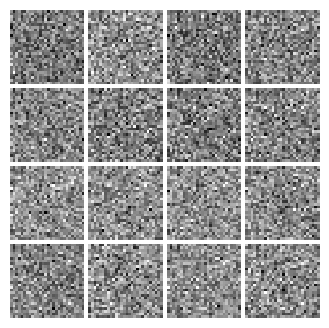


Iter: 250, D loss: 0.1918, G loss:0.2942


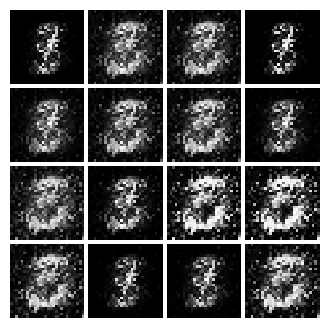


epoch:  2
Iter: 500, D loss: 0.2003, G loss:0.3427


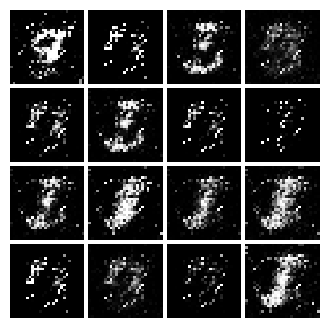


Iter: 750, D loss: 0.1834, G loss:0.6529


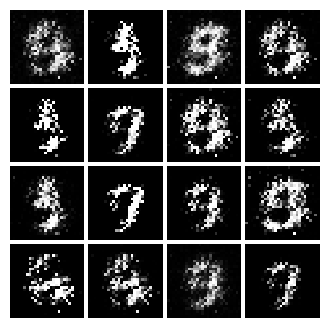


epoch:  3
Iter: 1000, D loss: 0.1713, G loss:0.2321


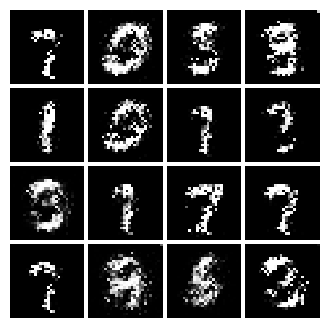


epoch:  4
Iter: 1250, D loss: 0.1984, G loss:0.247


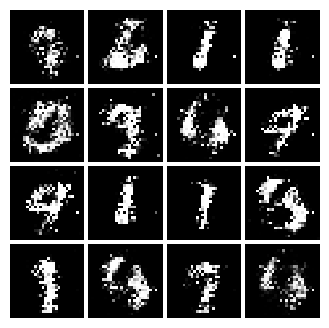


Iter: 1500, D loss: 0.2185, G loss:0.1845


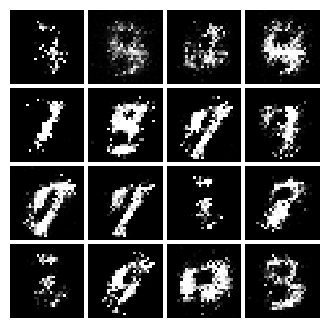


epoch:  5
Iter: 1750, D loss: 0.2238, G loss:0.1725


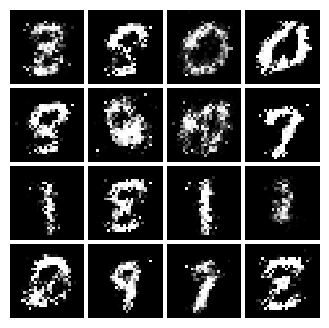


epoch:  6
Iter: 2000, D loss: 0.2349, G loss:0.1671


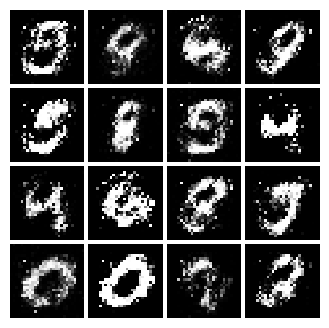


Iter: 2250, D loss: 0.24, G loss:0.1545


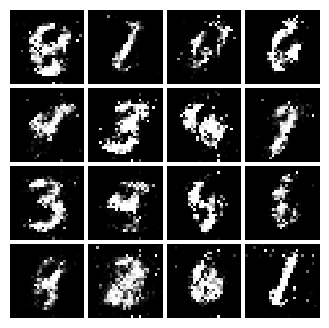


epoch:  7
Iter: 2500, D loss: 0.243, G loss:0.1808


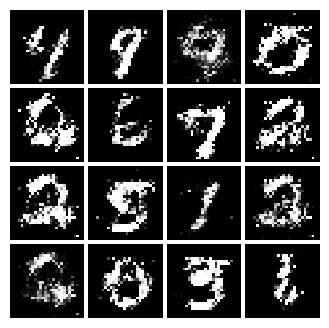


epoch:  8
Iter: 2750, D loss: 0.2193, G loss:0.175


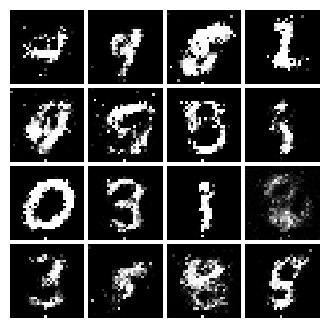


Iter: 3000, D loss: 0.2147, G loss:0.1643


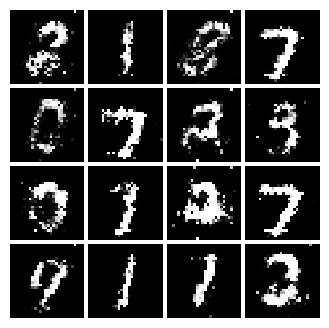


epoch:  9
Iter: 3250, D loss: 0.2169, G loss:0.1743


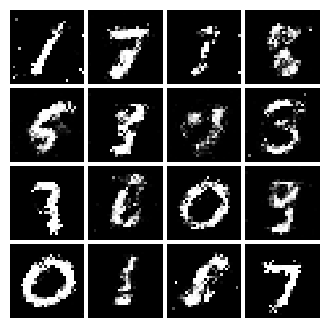


Iter: 3500, D loss: 0.2358, G loss:0.1648


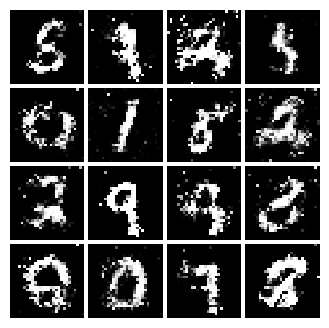


epoch:  10
Iter: 3750, D loss: 0.2416, G loss:0.1357


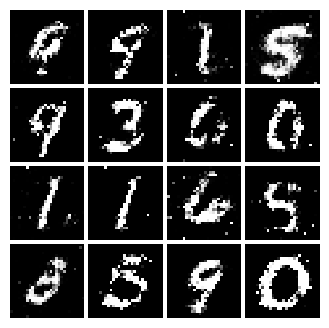


training done


In [40]:
base_dir = 'ls_gan'

train_gan(D, G, base_dir, noise_size=NOISE_DIM, num_epochs=10)

**EXPECTED OUTPUT**:
<pre>
Both Discriminator Loss and Generator Loss should start at around 0.5 and ends at around 0.2 in 10 epochs.

Train more to get better result.</pre>

<img src="https://i.imgur.com/QWGijqN.png" width="200"><img src="https://i.imgur.com/oqcBYUa.png" width="200">

You should see that using LS-GAN, the generated image looks more sharp and clearly recognizable compared to Vanilla GAN.

---
## 4 - Generate GIF

Now this just for fun, we combine the saved image generated from the same initial seed each epoch while training into a GIF animation

GIF saved as ls_gan.gif


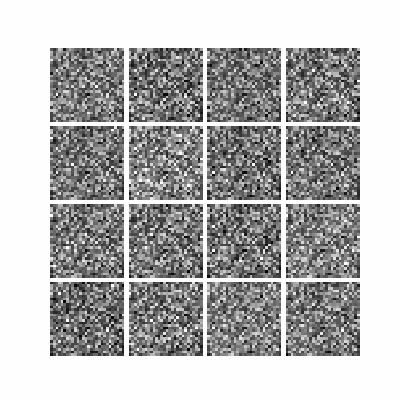

In [41]:
base_dir = 'ls_gan'

show_gif(base_dir, 'ls_gan.gif')

---
---
# [Part 6] Deeply Convolutional GANs
In the first part of the notebook, we implemented an almost direct copy of the original GAN network from Ian Goodfellow.

However, this network architecture allows no real spatial reasoning. It is unable to reason about things like "sharp edges" in general because it lacks any convolutional layers.

Thus, in this section, we will implement some of the ideas from [DCGAN](https://arxiv.org/abs/1511.06434), where we use convolutional networks

---
## 1 - DC-Discriminator Model

We will use a 4 layer ConvNet as our Discriminator Network

The architecture is as follow:<pre>
  <b>Conv2D</b> layer with <font color='blue'><b>32</b></font> filters of <font color='blue'><b>5x5</b></font> stride <font color='blue'><b>1</b></font> and <b>LeakyReLU</b> with alpha <font color='blue'><b>0.01</b></font>
  <b>Max Pool</b> layer with kernel size of <font color='blue'><b>2x2</b></font> stride <font color='blue'><b>2</b></font>
  <b>Conv2D</b> layer with <font color='blue'><b>64</b></font> filters of <font color='blue'><b>5x5</b></font> stride <font color='blue'><b>1</b></font> and <b>LeakyReLU</b> with alpha <font color='blue'><b>0.01</b></font>
  <b>Max Pool</b> layer with kernel size of <font color='blue'><b>2x2</b></font> stride <font color='blue'><b>2</b></font>
  <b>Flatten</b> layer to reshape activation into vector
  <b>Linear</b> layer with input and output size of <font color='blue'><b>4\*4\*64</b></font> followed by <b>LeakyReLU</b> with alpha <font color='blue'><b>0.01</b></font>
  <b>Linear</b> layer with input size <font color='blue'><b>4\*4\*64</b></font> and output size <font color='blue'><b>1</b></font>,
</pre>


---
#### <font color='red'>**EXERCISE:** </font>
Build and return a PyTorch model implementing the architecture above.


In [42]:
def dc_discriminator():

    return nn.Sequential(
        # add Conv2d() with 32 Filters, kernel size 5, and Stride 1
        # (from input channel = 1)
        nn.Conv2d(1, 32, kernel_size=5, stride=1),

        # add Leaky ReLU with alpha=0.01
        nn.LeakyReLU(0.01),

        # add MaxPool2d() with kernel size 2, Stride 2
        nn.MaxPool2d(kernel_size=2, stride=2),

        # add Conv2d() with 64 Filters, kernel size 5, and Stride 1
        nn.Conv2d(32, 64, kernel_size=5, stride=1),

        # add Leaky ReLU with alpha=0.01
        nn.LeakyReLU(0.01),

        # add MaxPool2d() with kernel size 2x2, Stride 2
        nn.MaxPool2d(kernel_size=2, stride=2),

        # add Flatten() layer
        nn.Flatten(),

        # add Linear layer with both input and output size 4*4*64
        nn.Linear(4 * 4 * 64, 4 * 4 * 64),

        # add Leaky ReLU with alpha=0.01
        nn.LeakyReLU(0.01),

        # add Linear layer with input 4*4*64 and output 1
        nn.Linear(4 * 4 * 64, 1)

    )

Test to make sure the number of parameters in the discriminator is correct:

In [43]:
model = dc_discriminator()

clean_summary(model, (1, 1, 28, 28))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                                                                                   --
├─Conv2d: 1-1                            [1, 1, 28, 28]            [1, 32, 24, 24]           832
├─LeakyReLU: 1-2                         [1, 32, 24, 24]           [1, 32, 24, 24]           --
├─MaxPool2d: 1-3                         [1, 32, 24, 24]           [1, 32, 12, 12]           --
├─Conv2d: 1-4                            [1, 32, 12, 12]           [1, 64, 8, 8]             51,264
├─LeakyReLU: 1-5                         [1, 64, 8, 8]             [1, 64, 8, 8]             --
├─MaxPool2d: 1-6                         [1, 64, 8, 8]             [1, 64, 4, 4]             --
├─Flatten: 1-7                           [1, 64, 4, 4]             [1, 1024]                 --
├─Linear: 1-8                            [1, 1024]                 [1, 1024]                 1,049,600
├─LeakyReLU: 1-9       

**Expected Result**:
<pre>
================================================================================
Layer (type:depth-idx)       Input Shape       Output Shape       Param #
================================================================================
Sequential                                                        --
├─Conv2d: 1-1                [1, 1, 28, 28]    [1, 32, 24, 24]    832
├─LeakyReLU: 1-2             [1, 32, 24, 24]   [1, 32, 24, 24]    --
├─MaxPool2d: 1-3             [1, 32, 24, 24]   [1, 32, 12, 12]    --
├─Conv2d: 1-4                [1, 32, 12, 12]   [1, 64, 8, 8]      51,264
├─LeakyReLU: 1-5             [1, 64, 8, 8]     [1, 64, 8, 8]      --
├─MaxPool2d: 1-6             [1, 64, 8, 8]     [1, 64, 4, 4]      --
├─Flatten: 1-7               [1, 64, 4, 4]     [1, 1024]          --
├─Linear: 1-8                [1, 1024]         [1, 1024]          1,049,600
├─LeakyReLU: 1-9             [1, 1024]         [1, 1024]          --
├─Linear: 1-10               [1, 1024]         [1, 1]             1,025
================================================================================
Total params: 1,102,721                                        
Trainable params: 1,102,721

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:20604): Pango-WARNING **: 19:56:54.297: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


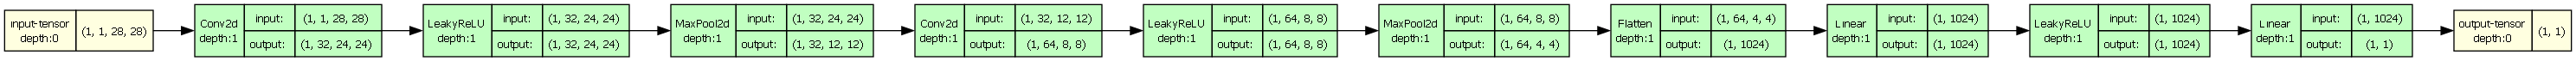

In [44]:
graphviz_bin = r'C:\Program Files\Graphviz\bin'
if os.path.isdir(graphviz_bin):
    os.environ['PATH'] = graphviz_bin + os.pathsep + os.environ.get('PATH', '')

model_graphq = draw_graph(model, input_size=(1, 1, 28, 28), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("model_d2", format="png")
display(Image(filename="model_d2.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/dUAvf3Q.png" width="800">

---
## 2 - DC-Generator Model
For the generator, we will copy the architecture exactly from the [InfoGAN paper](https://arxiv.org/pdf/1606.03657.pdf).

The architecture is as follow:<pre>
  <b>Linear</b> layer with <font color='blue'><b>1024</b></font> neurons and <b>ReLU</b> activation
  <b>BatchNorm1D</b> layer
  <b>Linear</b> layer with <font color='blue'><b>128\*7\*7</b></font> neurons and <b>ReLU</b> activation
  <b>BatchNorm1D</b> layer
  <b>Unflatten</b> layer to reshape activation into <font color='blue'><b>(128,7,7)</b></font>
  <b>Conv2DTranspose</b> layer with <font color='blue'><b>64</b></font> filters of <font color='blue'><b>4x4</b></font> using stride <font color='blue'><b>2</b></font>, padding <font color='blue'><b>1</b></font> and <b>ReLU</b> activation
  <b>BatchNorm2D</b> layer
  <b>Conv2DTranspose</b> layer with <font color='blue'><b>1</b></font> filters of <font color='blue'><b>4x4</b></font> using stride <font color='blue'><b>2</b></font>, padding <font color='blue'><b>1</b></font> and <b>TanH</b> activation
  <b>Flatten</b> layer to reshape activation into <font color='blue'><b>784</b></font> vector
</pre>


<font size=3><b> Something Weird? </b></font>

You might notice that the generator architecture flattens back it's already made output image of $(1,28,28)$ into a 1D vector of $(784,)$

*weird, huh?*

<br>

Well, we need to reshape it back since we made our training function to receive and save images from a vector-shaped output from the previously Vanilla GAN

Since we don't want to change the training function just for this DC-GAN, it's easier to design the generator model to just return a vector

---
#### <font color='red'>**EXERCISE:** </font>
Build and return a PyTorch model implementing the architecture above.

In [45]:
def dc_generator(noise_dim=NOISE_DIM):

    return nn.Sequential(

        # add Linear() with input noise_dim and output 1024
        nn.Linear(noise_dim, 1024),

        # add ReLU()
        nn.ReLU(),

        # add BatchNorm1d() with input 1024
        nn.BatchNorm1d(1024),

        # add Linear() with input 1024 and output 7*7*128
        nn.Linear(1024, 7 * 7 * 128),

        # add ReLU()
        nn.ReLU(),

        # add BatchNorm1d() with input 7*7*128
        nn.BatchNorm1d(7 * 7 * 128),

        # add Unflatten() with input dim 1 and unflattened_size=(128, 7, 7)
        nn.Unflatten(1, (128, 7, 7)),

        # add ConvTranspose2d() with input channel = 128, 64 Filters,
        # 4x4 kernel, stride 2, and padding 1
        nn.ConvTranspose2d(128, 64, kernel_size=4, stride=2, padding=1),

        # add ReLU()
        nn.ReLU(),

        # add BatchNorm2d() with input 64
        nn.BatchNorm2d(64),

        # add ConvTranspose2d() with input channel = 64, 1 Filter,
        # 4x4 kernel, stride 2, and padding 1
        nn.ConvTranspose2d(64, 1, kernel_size=4, stride=2, padding=1),

        # add Tanh()
        nn.Tanh(),

        # add final Flatten() for training
        nn.Flatten()

    )


Test to make sure the number of parameters in the discriminator is correct:

In [46]:
model = dc_generator(4)

clean_summary(model, (1,4))

Layer (type:depth-idx)                   Input Shape               Output Shape              Param #
Sequential                                                                                   --
├─Linear: 1-1                            [1, 4]                    [1, 1024]                 5,120
├─ReLU: 1-2                              [1, 1024]                 [1, 1024]                 --
├─BatchNorm1d: 1-3                       [1, 1024]                 [1, 1024]                 2,048
├─Linear: 1-4                            [1, 1024]                 [1, 6272]                 6,428,800
├─ReLU: 1-5                              [1, 6272]                 [1, 6272]                 --
├─BatchNorm1d: 1-6                       [1, 6272]                 [1, 6272]                 12,544
├─Unflatten: 1-7                         [1, 6272]                 [1, 128, 7, 7]            --
├─ConvTranspose2d: 1-8                   [1, 128, 7, 7]            [1, 64, 14, 14]           131,136
├─ReLU: 1-9  

**Expected Result**:

<pre>
================================================================================
Layer (type:depth-idx)       Input Shape       Output Shape       Param #
================================================================================
Sequential                                                        --
├─Linear: 1-1                [1, 4]            [1, 1024]          5,120
├─ReLU: 1-2                  [1, 1024]         [1, 1024]          --
├─BatchNorm1d: 1-3           [1, 1024]         [1, 1024]          2,048
├─Linear: 1-4                [1, 1024]         [1, 6272]          6,428,800
├─ReLU: 1-5                  [1, 6272]         [1, 6272]          --
├─BatchNorm1d: 1-6           [1, 6272]         [1, 6272]          12,544
├─Unflatten: 1-7             [1, 6272]         [1, 128, 7, 7]     --
├─ConvTranspose2d: 1-8       [1, 128, 7, 7]    [1, 64, 14, 14]    131,136
├─ReLU: 1-9                  [1, 64, 14, 14]   [1, 64, 14, 14]    --
├─BatchNorm2d: 1-10          [1, 64, 14, 14]   [1, 64, 14, 14]    128
├─ConvTranspose2d: 1-11      [1, 64, 14, 14]   [1, 1, 28, 28]     1,025
├─Tanh: 1-12                 [1, 1, 28, 28]    [1, 1, 28, 28]     --
├─Flatten: 1-13              [1, 1, 28, 28]    [1, 784]           --
================================================================================
Total params: 6,580,801
Trainable params: 6,580,801

Visualize the network architecture in graphical form.

Click the image to enlarge


(process:19532): Pango-WARNING **: 19:56:54.789: couldn't load font "Linux libertine Not-Rotated 10", falling back to "Sans Not-Rotated 10", expect ugly output.


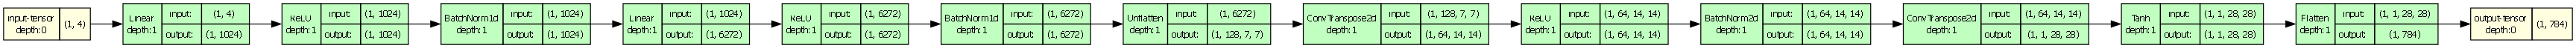

In [47]:
graphviz_bin = r'C:\Program Files\Graphviz\bin'
if os.path.isdir(graphviz_bin):
    os.environ['PATH'] = graphviz_bin + os.pathsep + os.environ.get('PATH', '')

model_graphq = draw_graph(model, input_size=(1, 4), expand_nested=True, graph_dir="LR")
model_graphq.resize_graph(scale=3)

model_graphq.visual_graph.render("model_g2", format="png")
display(Image(filename="model_g2.png"))

**Expected Output**:
<pre>
output image should be something like this

<img src="https://i.imgur.com/E6chjgx.png" width="800">

---
## 3 - Train DC-GAN
Initialize newly designed DC Generator and Discriminator models

In [48]:
# Make new discriminator model
D_DC = dc_discriminator().to(device)

# Make new generator model
G_DC = dc_generator().to(device)

# apply weight initialization
G_DC.apply(initialize_weights)
D_DC.apply(initialize_weights)

# Use the get_optimizer() function to get optimizers for the Discriminator and the Generator
D_DC_solver = get_optimizer(D_DC)
G_DC_solver = get_optimizer(G_DC)

# pack the model into tuple
D = ( D_DC, D_DC_solver, discriminator_loss )
G = ( G_DC, G_DC_solver, generator_loss )

Train our DC-GAN models also for 10 epochs.

You should see much better resuts in just 5 epochs.

start training
epoch:  1
Iter: 0, D loss: 1.372, G loss:1.399


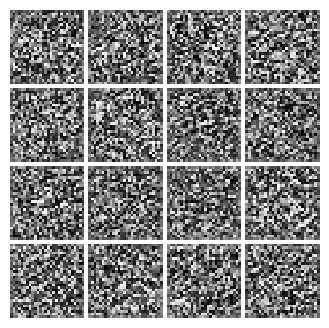


Iter: 250, D loss: 1.259, G loss:0.8075


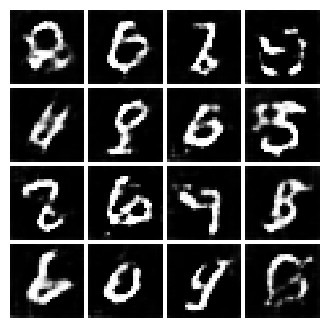


epoch:  2
Iter: 500, D loss: 1.257, G loss:1.24


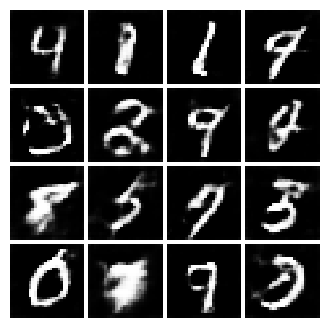


Iter: 750, D loss: 1.137, G loss:1.032


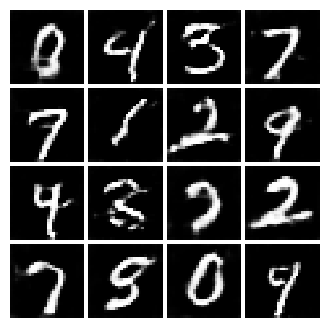


epoch:  3
Iter: 1000, D loss: 1.282, G loss:0.8373


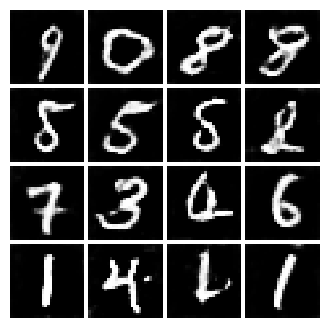


epoch:  4
Iter: 1250, D loss: 1.221, G loss:1.116


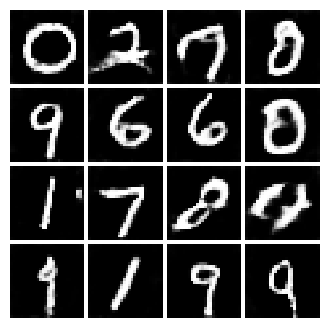


Iter: 1500, D loss: 1.16, G loss:1.067


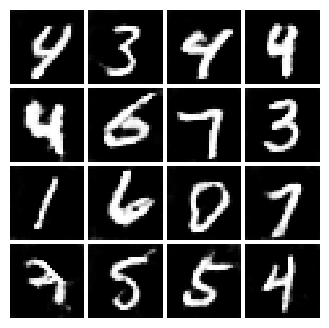


epoch:  5
Iter: 1750, D loss: 1.07, G loss:0.8454


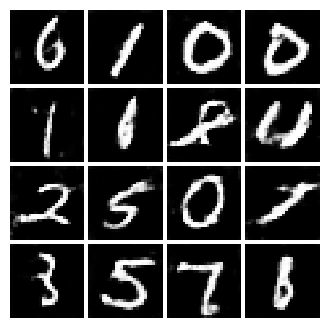


epoch:  6
Iter: 2000, D loss: 1.207, G loss:0.8969


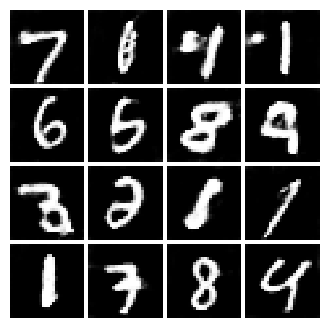


Iter: 2250, D loss: 1.071, G loss:1.252


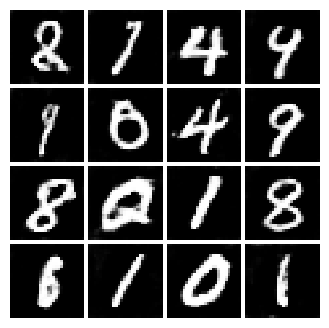


epoch:  7
Iter: 2500, D loss: 1.116, G loss:1.265


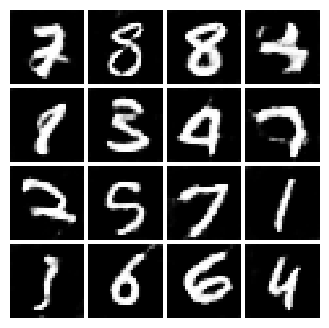


epoch:  8
Iter: 2750, D loss: 0.9987, G loss:1.152


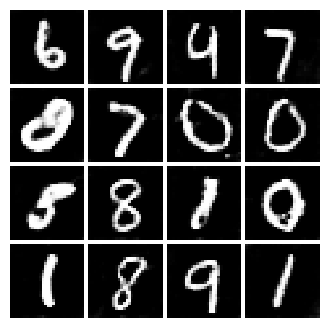


Iter: 3000, D loss: 1.087, G loss:1.024


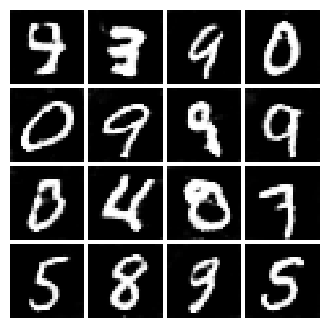


epoch:  9
Iter: 3250, D loss: 0.9044, G loss:1.341


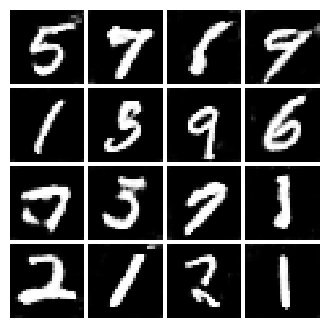


Iter: 3500, D loss: 0.9638, G loss:1.568


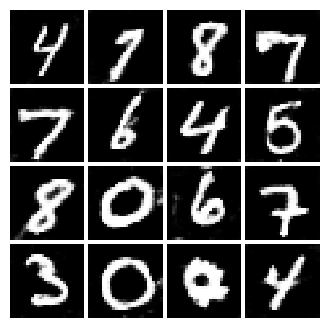


epoch:  10
Iter: 3750, D loss: 1.183, G loss:0.7912


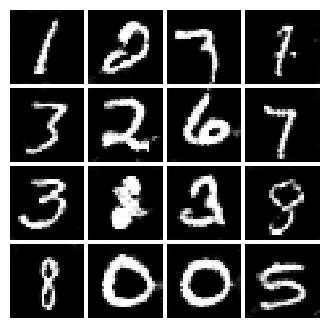


training done


In [49]:
base_dir = 'dc_gan'

train_gan(D, G, base_dir, noise_size=NOISE_DIM, num_epochs=10)

**EXPECTED OUTPUT**:
<pre>
Both Discriminator Loss and Generator Loss should start at around 1.4 and ends at around 1.0 in 10 epochs.

Train more to get even better result.</pre>

<img src="https://i.imgur.com/qsAmWRq.png" width="200"><img src="https://i.imgur.com/RU0Drvj.png" width="200">

You should see that now using DC-GAN, from the start, the generated image looks much more clean and natural compared to using Linear GAN.

---
## 4 - Generate GIF

Now this just for fun, we combine the saved image generated from the same initial seed each epoch while training into a GIF animation

GIF saved as dc_gan.gif


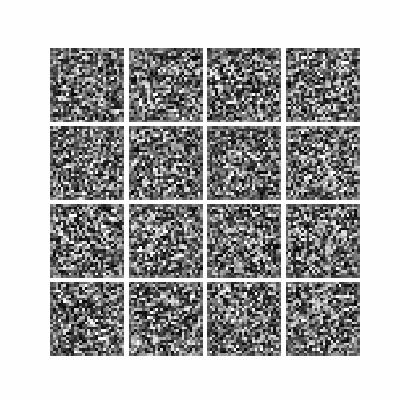

In [50]:
base_dir = 'dc_gan'

show_gif(base_dir, 'dc_gan.gif')

Pretty Neat, eh?

---
---
# [Part 7] Generate new Images

Let's see the result of our GAN with the same sample seed start

---
## 1 - Generate random noise


In [51]:
fake_seed = sample_noise(128, 96)

print(fake_seed.shape)

torch.Size([128, 96])


Example of seed of an image

In [52]:
print(fake_seed[0])

tensor([-0.1867,  0.8050,  0.6878, -0.6347, -0.1433,  0.1356,  0.8218, -0.4046,
        -0.1628,  0.3520,  0.2495, -0.2978, -0.1058,  0.4066,  0.3415, -0.8481,
         0.6054,  0.3299,  0.3302,  0.0391, -0.7084, -0.8051, -0.0476,  0.4474,
         0.0257, -0.2704,  0.9495,  0.2871,  0.0582, -0.4003,  0.2482,  0.8517,
        -0.2401, -0.4573,  0.5320, -0.2693, -0.9300,  0.4668, -0.6892,  0.7461,
         0.5754,  0.0386, -0.4892, -0.1209, -0.9070, -0.0241,  0.6511, -0.2505,
         0.7164,  0.8817, -0.7118, -0.7287, -0.4023, -0.9727,  0.4899,  0.9824,
         0.9388,  0.5344,  0.5392,  0.9315,  0.9593,  0.0777,  0.0383,  0.1485,
        -0.5185,  0.6412,  0.9217, -0.4465,  0.3138,  0.1468,  0.6380, -0.1166,
         0.6016,  0.7099,  0.6711, -0.0723,  0.5077, -0.6957, -0.1473,  0.7860,
         0.0872,  0.4599, -0.9933, -0.3415, -0.7949,  0.8768,  0.9505,  0.9088,
        -0.3247, -0.8861, -0.1198,  0.3560, -0.7810,  0.6635, -0.2998, -0.1454])


---
## 2 - Vanilla GAN Generated Images

In [53]:
with torch.no_grad():
    fake_images = G_V(fake_seed)

print(fake_images.shape)

torch.Size([128, 784])


View the generated images

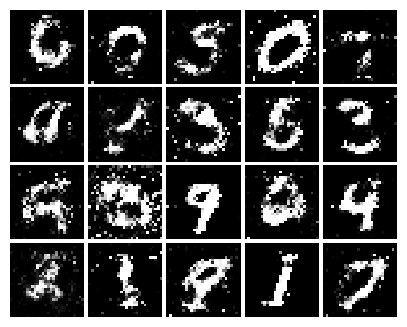

In [54]:
image_to_view = 20
imgs_numpy = fake_images.detach().cpu().numpy()
show_images(imgs_numpy[0:image_to_view])
plt.show()

**Expected Output**:
<pre>
output image should be something like this
<img src="https://i.imgur.com/erwrL89.png" width="200">

We can generate single image from a vector of fake seed

Vanilla GAN generated image
from seed tensor([-0.9564, -0.7497, -0.7914, -0.3476]) ...



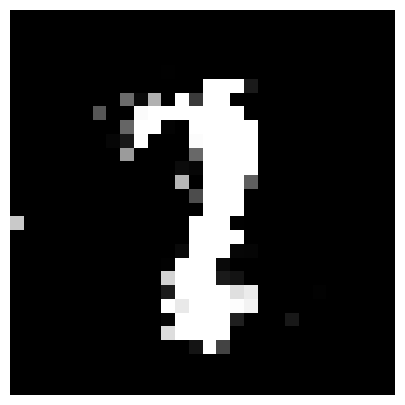

In [55]:
single_seed = sample_noise(1, 96)
print('Vanilla GAN generated image\nfrom seed', single_seed[0,:4],'...\n')

with torch.no_grad():
    fake_images = G_V(single_seed)
imgs_numpy = fake_images.detach().cpu().numpy()

plt.figure(figsize=(5,5))
plt.imshow(imgs_numpy.reshape((28,28)))
plt.axis('off')
plt.show()


---
## 3 - LS-GAN Generated Images


In [56]:
with torch.no_grad():
    fake_images = G_LS(fake_seed)

print(fake_images.shape)

torch.Size([128, 784])


View the generated images

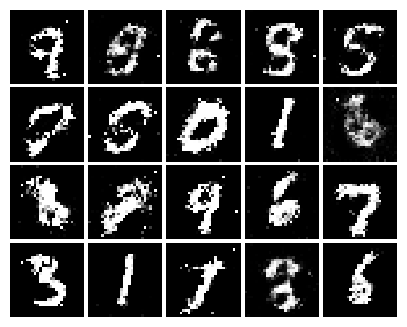

In [57]:
image_to_view = 20
imgs_numpy = fake_images.detach().cpu().numpy()
show_images(imgs_numpy[0:image_to_view])
plt.show()

**Expected Output**:
<pre>
output image should be something like this
<img src="https://i.imgur.com/yYPpFMp.png" width="200">

We can generate single image from a vector of fake seed

LS GAN generated image
from seed tensor([ 0.0382,  0.9585, -0.8350, -0.2501]) ...



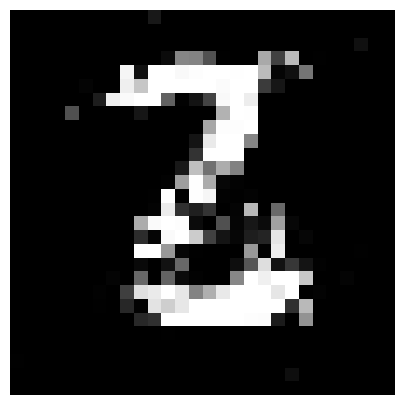

In [58]:
single_seed = sample_noise(1, 96)
print('LS GAN generated image\nfrom seed', single_seed[0,:4],'...\n')

single_seed = single_seed.to(device)
with torch.no_grad():
    fake_images = G_LS(single_seed)
imgs_numpy = fake_images.detach().cpu().numpy()

plt.figure(figsize=(5,5))
plt.imshow(imgs_numpy.reshape((28,28)))
plt.axis('off')
plt.show()


---
## 4 - DC-GAN Generated Images


In [59]:
with torch.no_grad():
  fake_images = G_DC(fake_seed)

print(fake_images.shape)

torch.Size([128, 784])


View the generated images

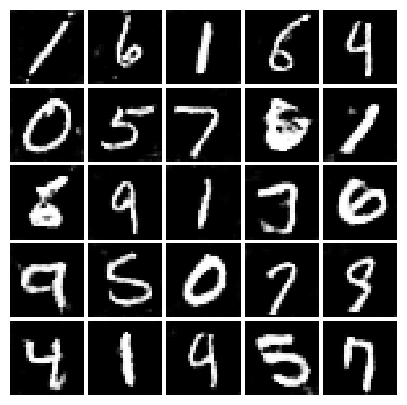

In [60]:
image_to_view = 25
imgs_numpy = fake_images.detach().cpu().numpy()
show_images(imgs_numpy[0:image_to_view])
plt.show()

**Expected Output**:
<pre>
output image should be something like this
<img src="https://i.imgur.com/b3WKumn.png" width="200">

Looks great isn't it?

Now let's compare it to the real MNIST dataset

In [61]:
imgs = next(iter(loader_train))[0]
imgs = imgs.view(batch_size, 784).numpy().squeeze()
print(imgs.shape)

(128, 784)


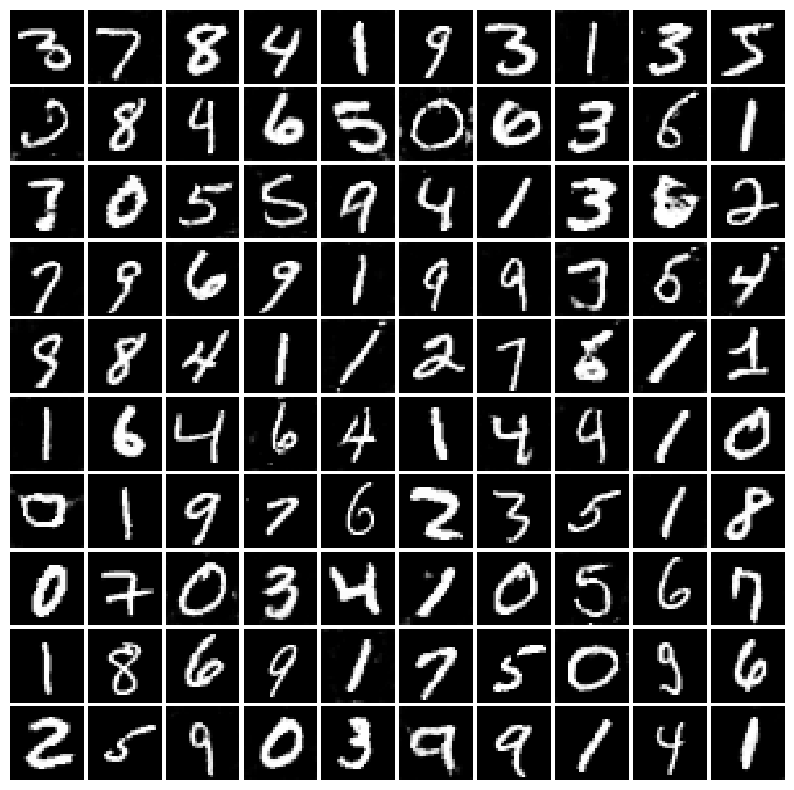

In [62]:
combined = np.vstack([imgs_numpy[:50,:], imgs[:50,:]])
idx = np.arange(combined.shape[0])
np.random.shuffle(idx)
combined = combined[idx]
show_images(combined[:100])
plt.show()

<font size=6> The images above are the combination between generated images and the real MNIST images.</font>

Can you tell which are the original images and which are the fake ones?

Can you tell the difference?


---
Run the code below to see the answer

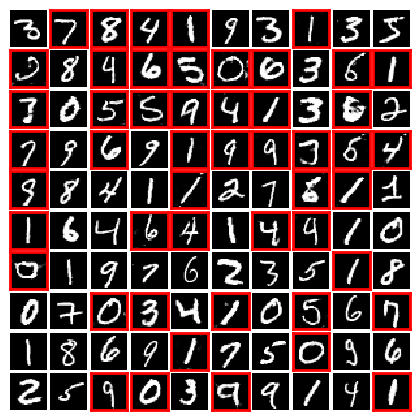

In [63]:
labels = np.concatenate([np.zeros(50), np.ones(50)])
labels = labels[idx]

fig, axes = plt.subplots(10, 10, figsize=(4, 4),
                         gridspec_kw={'wspace': 0.1, 'hspace': 0.1})
axes = axes.flatten()

for i in range(100):
    ax = axes[i]
    ax.imshow(combined[i].reshape(28, 28))
    if labels[i] == 0:
        ax.set_xticks([])
        ax.set_yticks([])
        for spine in ax.spines.values():
            spine.set_color('red')
            spine.set_linewidth(2)
    else:
        ax.axis('off')

plt.subplots_adjust(left=0, right=1, bottom=0, top=1)
plt.show()

---
---

# Congratulation, You've Completed Exercise 6

<p>Copyright &copy;  <a href=https://www.linkedin.com/in/andityaarifianto/>2026 - ADF</a> </p>

![footer](https://i.imgur.com/UU76cTP.png)